In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import joblib

In [2]:
# Load dataset
cancer = load_breast_cancer()

# Convert dataset into DataFrame
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Add target column
df["target"] = cancer.target

# Display dataset
display(df.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


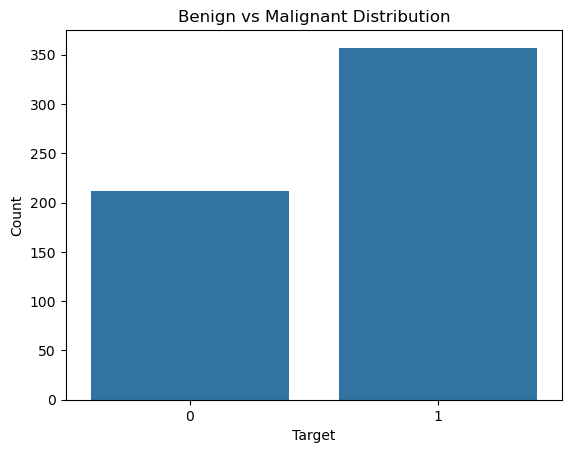

Target Names: ['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


In [3]:
sns.countplot(x="target", data=df)

plt.title("Benign vs Malignant Distribution")
plt.xlabel("Target")
plt.ylabel("Count")

plt.show()

print("Target Names:", cancer.target_names)
print(df["target"].value_counts())

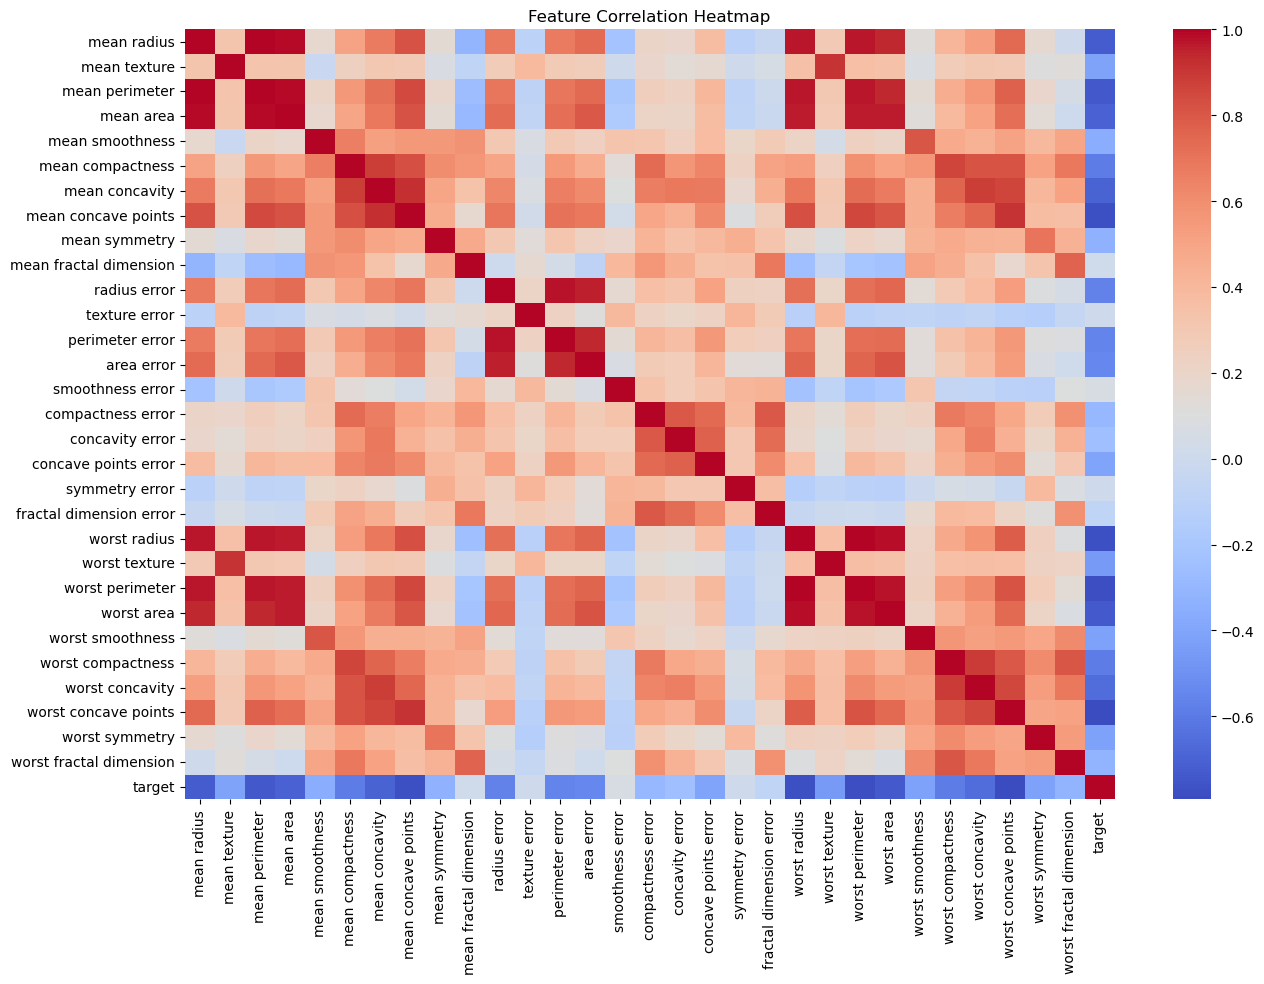

In [5]:

plt.figure(figsize=(15, 10))

sns.heatmap(
    df.corr(),
    cmap="coolwarm",
    annot=False
)

plt.title("Feature Correlation Heatmap")
plt.show()


In [6]:
# Input features
X = df.drop("target", axis=1)

# Output target
y = df["target"]

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (569, 30)
Output Shape: (569,)


In [8]:
# First split: 80% training + validation, 20% testing

X_temp, X_test, y_temp, y_test = train_test_split(
X,
y,
test_size=0.20,
random_state=42,
stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
X_temp,
y_temp,
test_size=0.25,
random_state=42,
stratify=y_temp
)

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)

Training Data: (341, 30)
Validation Data: (114, 30)
Testing Data: (114, 30)


In [9]:
# Create Logistic Regression model
baseline_model = LogisticRegression(
    max_iter=5000
)

# Train the model
baseline_model.fit(X_train, y_train)

# Predict validation data
baseline_pred = baseline_model.predict(X_val)

# Calculate accuracy
baseline_accuracy = accuracy_score(
    y_val,
    baseline_pred
)

print("Baseline Model Accuracy:",
      baseline_accuracy)

Baseline Model Accuracy: 0.9473684210526315


In [10]:
cv_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Cross Validation Scores:", cv_scores)

print("Cross Validation Mean:",
      cv_scores.mean())

print("Cross Validation Standard Deviation:",
      cv_scores.std())

Cross Validation Scores: [0.97101449 0.95588235 0.98529412 0.94117647 0.95588235]
Cross Validation Mean: 0.9618499573742542
Cross Validation Standard Deviation: 0.015048156171755624


In [11]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

# Train pipeline
pipeline.fit(X_train, y_train)

# Predict validation data
pipeline_pred = pipeline.predict(X_val)

# Calculate accuracy
pipeline_accuracy = accuracy_score(
    y_val,
    pipeline_pred
)

print("Pipeline Accuracy:", pipeline_accuracy)

Pipeline Accuracy: 0.9912280701754386
